<a href="https://colab.research.google.com/github/GavrilLaura/PMP-2026/blob/main/Lab06/pmp_lab6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAB 6 - Inferenţă Bayesiană

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import arviz as az

In [ ]:
n_ore = 10
total_apeluri = 180

alpha_prior = 2
beta_prior = 0.1

print(f"Media observata: {total_apeluri / n_ore} apeluri/ora")
print(f"Prior: Gamma({alpha_prior}, {beta_prior}) -> media = {alpha_prior / beta_prior}")

Media observata: 18.0 apeluri/ora
Prior: Gamma(2, 0.1) -> media = 20.0


In [ ]:
alpha_post = alpha_prior + total_apeluri
beta_post = beta_prior + n_ore

prior = stats.gamma(a=alpha_prior, scale=1 / beta_prior)
posterior = stats.gamma(a=alpha_post, scale=1 / beta_post)

print(f"Posterior: Gamma({alpha_post}, {beta_post})")
print(f"Media posteriorului: {posterior.mean():.3f}")
print(f"Deviatia standard:   {posterior.std():.3f}")

Posterior: Gamma(182, 10.1)
Media posteriorului: 18.020
Deviatia standard:   1.336


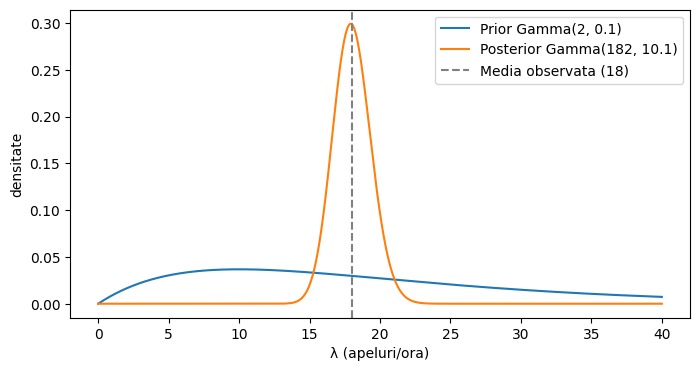

In [ ]:
x = np.linspace(0, 40, 1000)

plt.figure(figsize=(8, 4))
plt.plot(x, prior.pdf(x), label=f"Prior Gamma({alpha_prior}, {beta_prior})")
plt.plot(x, posterior.pdf(x), label=f"Posterior Gamma({alpha_post}, {beta_post})")
plt.axvline(total_apeluri / n_ore, color="gray", linestyle="--", label="Media observata (18)")
plt.xlabel("λ (apeluri/ora)")
plt.ylabel("densitate")
plt.legend()
plt.show()

In [ ]:
mod_analitic = (alpha_post - 1) / beta_post
print(f"Modul (analitic): {mod_analitic:.3f}")

np.random.seed(42)
esantioane = posterior.rvs(size=10000)

Modul (analitic): 17.921


HDI 94%: [15.69, 20.68]


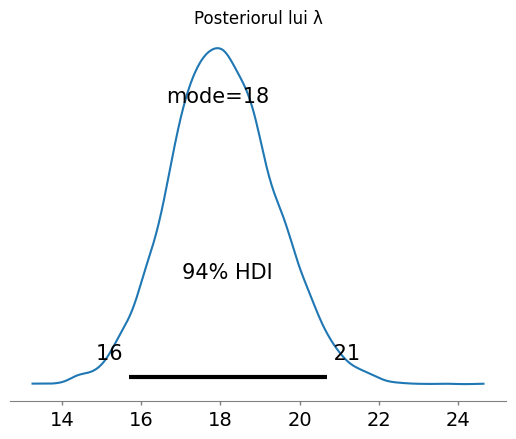

In [ ]:
hdi = az.hdi(esantioane, hdi_prob=0.94)
print(f"HDI 94%: [{hdi[0]:.2f}, {hdi[1]:.2f}]")

az.plot_posterior(esantioane, hdi_prob=0.94, point_estimate="mode")
plt.title("Posteriorul lui λ")
plt.show()